In [11]:
%load_ext autoreload
%autoreload 2

import os
import sys
module_path = os.path.abspath(os.path.join('../..'))
if module_path not in sys.path:
    sys.path.append(module_path)

from pathlib import Path
import jax
import jax.numpy as jnp
from flax.training import checkpoints
from agents.a2c_rnn_flax import init_network_and_params
from environments.components.train_state import create_train_state
import matplotlib.pyplot as plt
from nb_analysis_tools import load_trajectory_data, parse_behavioral_data
import numpy as np
from sklearn.decomposition import PCA
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize
from mpl_toolkits.mplot3d.art3d import Line3DCollection
import seaborn as sns
from nb_dynamics_plotting import *

plt.rcParams['font.family'] = 'Helvetica Light'

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [12]:
FIGURES_DIR = Path('../../../figures/motifs_analysis')
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


In [13]:
HIDDEN_SIZE = 64
ACTION_SIZE = 2
OBS_SIZE    = 4
RNN_TYPE    = 'GRU'
SEED        = 0

rng_key = jax.random.key(SEED)
net_init_key, rng_key = jax.random.split(rng_key)

network, params = init_network_and_params(
    hidden_size=HIDDEN_SIZE,
    action_size=ACTION_SIZE,
    obs_size=OBS_SIZE,
    rnn_type=RNN_TYPE,
    unit_noise_std=0.0,
    rng_key=net_init_key,
)

train_state = create_train_state(
    rng_key=rng_key,
    obs_size=OBS_SIZE,
    hidden_size=HIDDEN_SIZE,
    num_envs=1,
    learning_rate=0,
    params=params,
)

In [5]:
CKPT_DIR  = Path('../../../checkpoints/structure_evo_exp_gru_initial_prob_offset_reward_normed')
TRAJ_DIR  = Path('../../../results/structure_evo_exp_gru_initial_prob_offset_reward_normed')

# Find the highest-numbered checkpoint in step_00
import re
ckpt_paths = sorted(
    CKPT_DIR.glob('step_00/checkpoint_*'),
    key=lambda p: int(re.search(r'checkpoint_(\d+)$', p.name).group(1)),
)
final_ckpt = ckpt_paths[int(-450/25)]
session_abs = int(re.search(r'checkpoint_(\d+)$', final_ckpt.name).group(1))
final_traj  = TRAJ_DIR / 'step_00' / f'traj_{session_abs:06d}.pkl'

print(f'Final checkpoint : {final_ckpt}')
print(f'Trajectory file  : {final_traj}')
print(f'Trajectory exists: {final_traj.exists()}')

Final checkpoint : ../../../checkpoints/structure_evo_exp_gru_initial_prob_offset_reward_normed/step_00/checkpoint_1550
Trajectory file  : ../../../results/structure_evo_exp_gru_initial_prob_offset_reward_normed/step_00/traj_001550.pkl
Trajectory exists: True


In [14]:
traj_data_raw = load_trajectory_data(str(final_traj))
traj_data     = parse_behavioral_data(traj_data_raw[0])

pca = PCA()
pca.fit(traj_data['actor_hidden'])

restored   = checkpoints.restore_checkpoint(ckpt_dir=final_ckpt.resolve(), target=train_state)
net_params = restored.params

print('Hidden state shape:', traj_data['actor_hidden'].shape)
print('Variance explained by PC1-3: {:.1f}%'.format(
    pca.explained_variance_ratio_[:3].sum() * 100))

Hidden state shape: (20000, 64)
Variance explained by PC1-3: 72.5%


[[ 1.3823328e-02 -1.3518614e-03 -4.3839011e-03 -4.8722466e-03
   9.8573571e-01  1.2368801e-02  9.5120035e-03]
 [ 9.9285358e-01 -1.5337191e-02  1.4360083e-02 -2.1593099e-02
  -1.1951906e-03  9.9521029e-01 -1.2347975e-02]
 [ 9.8827624e-01 -5.5712126e-03  9.9788338e-01 -5.9315027e-03
   2.2168627e-02  1.0095862e+00 -5.2048266e-03]
 [ 1.0267432e+00 -9.1449898e-03  9.8953670e-01  4.8499559e-03
  -4.7158236e-03  1.0081872e+00  7.3299697e-03]
 [ 9.9622405e-01 -2.3861608e-02  1.0068998e+00 -5.5138483e-03
   4.4480795e-03  1.0033010e+00  3.6535144e-04]]
Trial 0, patch 2  (global steps 429–529, length 101)  → 101 segments with ≥2 steps


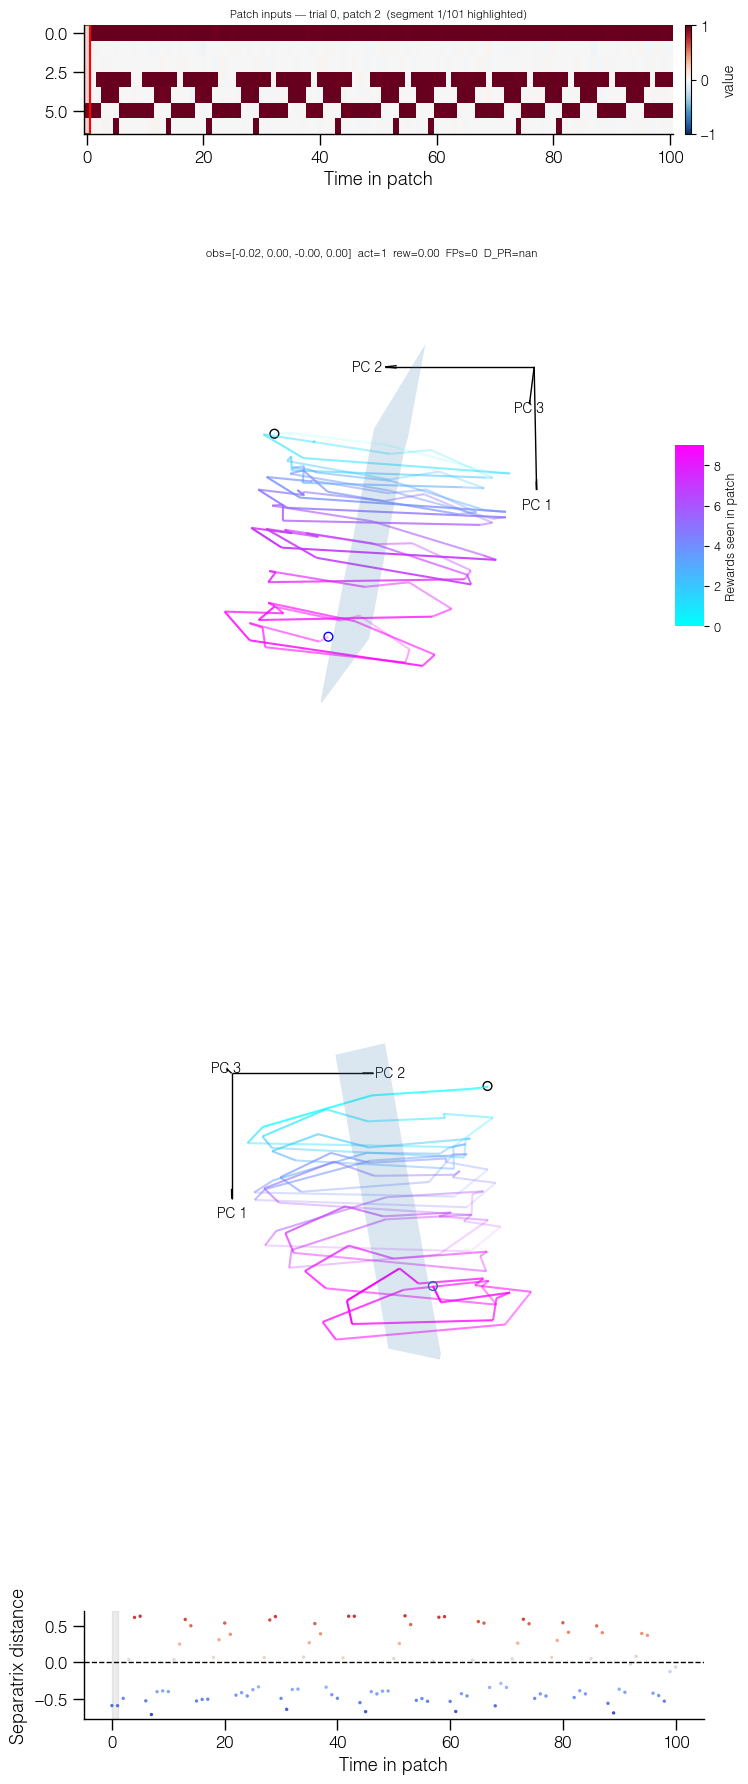

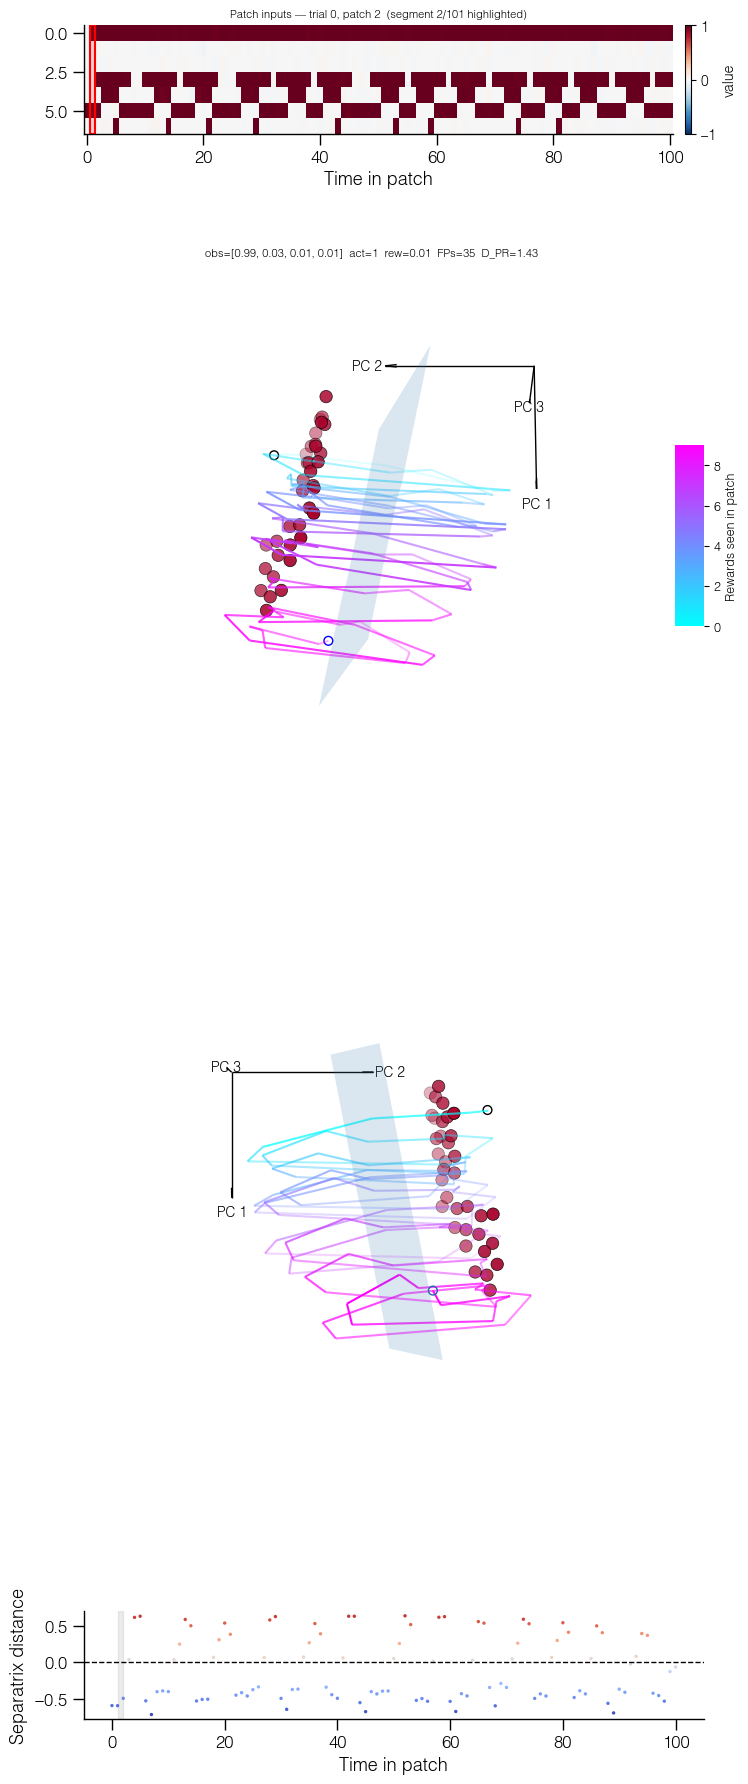

: 

In [ ]:
plot_patch_segments_with_fixed_points(
    traj_data, net_params, network, pca,
    trial_idx=0,
    patch_idx=2,
    patch_type=2,
    n_fp_attempts=300,
    unique_fp_tol=1.5e-1,
    fp_tol=2e-3,
    azim=180,
    elev=-110,
    azim2=365,
    elev2=90,
    includes_actions_and_rewards=True,
    stop_after_unique_inputs=True,
    round_inputs_for_uniqueness=True,
    traj_cmap=sns.color_palette(palette='cool', as_cmap=True),
    plot_current_segment=False,
    target_inputs=[
        None,
        [1, 0, 0, 0, 0, 1, 0],
    ],
    save_dir=str(FIGURES_DIR / 'patch_segments'),
    lw=1.5,
    fp_color='#a8032c',
)


[[ 1.3823328e-02 -1.3518614e-03 -4.3839011e-03 -4.8722466e-03
   9.8573571e-01  1.2368801e-02  9.5120035e-03]
 [ 9.9285358e-01 -1.5337191e-02  1.4360083e-02 -2.1593099e-02
  -1.1951906e-03  9.9521029e-01 -1.2347975e-02]
 [ 9.8827624e-01 -5.5712126e-03  9.9788338e-01 -5.9315027e-03
   2.2168627e-02  1.0095862e+00 -5.2048266e-03]
 [ 1.0267432e+00 -9.1449898e-03  9.8953670e-01  4.8499559e-03
  -4.7158236e-03  1.0081872e+00  7.3299697e-03]
 [ 9.9622405e-01 -2.3861608e-02  1.0068998e+00 -5.5138483e-03
   4.4480795e-03  1.0033010e+00  3.6535144e-04]]
Trial 0, patch 2  (global steps 429–529, length 101)  → 101 segments with ≥2 steps


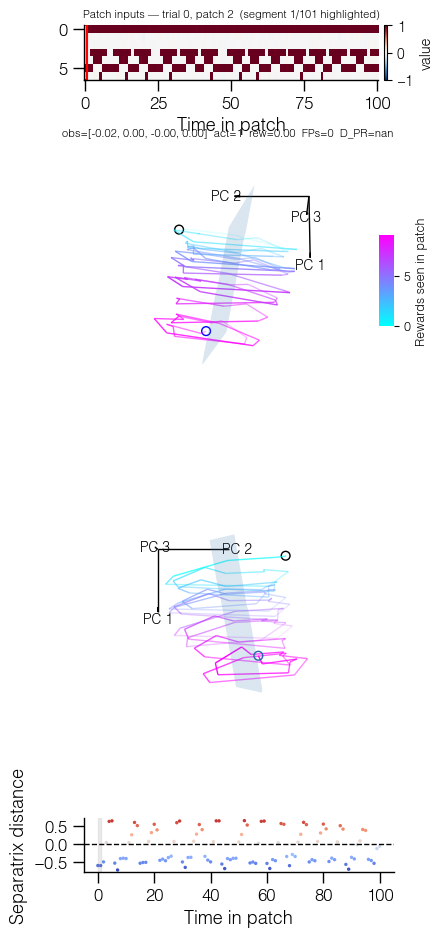

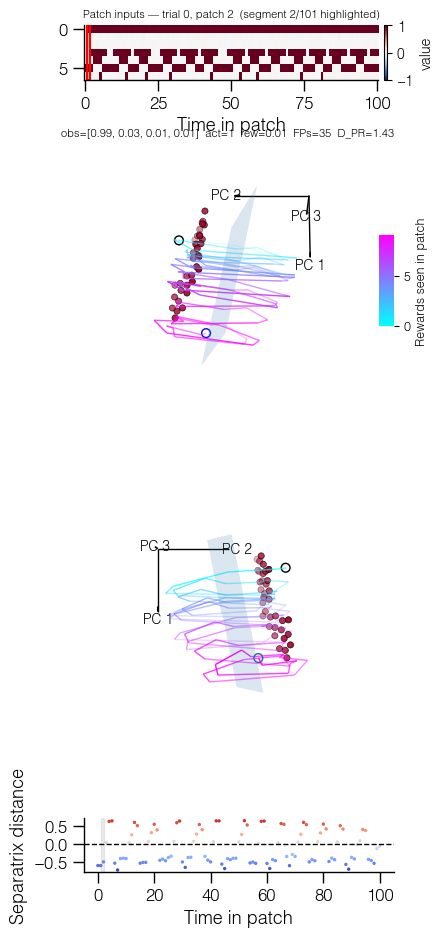

In [ ]:
plot_patch_segments_with_fixed_points(
    traj_data, net_params, network, pca,
    trial_idx=0,
    patch_idx=2,
    patch_type=2,
    n_fp_attempts=300,
    unique_fp_tol=1.5e-1,
    fp_tol=2e-3,
    azim=180,
    elev=-110,
    azim2=365,
    elev2=90,
    includes_actions_and_rewards=True,
    stop_after_unique_inputs=True,
    round_inputs_for_uniqueness=True,
    traj_cmap=sns.color_palette(palette='cool', as_cmap=True),
    plot_current_segment=False,
    target_inputs=[
        None,
        [1, 0, 0, 0, 0, 1, 0],
    ],
    scale=0.5,
    fp_marker_size=20,
    save_dir=str(FIGURES_DIR / 'patch_segments_small'),
    lw=1,
    fp_color='#a8032c',
)



[[ 1.3823328e-02 -1.3518614e-03 -4.3839011e-03 -4.8722466e-03
   9.8573571e-01  1.2368801e-02  9.5120035e-03]
 [ 9.9285358e-01 -1.5337191e-02  1.4360083e-02 -2.1593099e-02
  -1.1951906e-03  9.9521029e-01 -1.2347975e-02]
 [ 9.8827624e-01 -5.5712126e-03  9.9788338e-01 -5.9315027e-03
   2.2168627e-02  1.0095862e+00 -5.2048266e-03]
 [ 1.0267432e+00 -9.1449898e-03  9.8953670e-01  4.8499559e-03
  -4.7158236e-03  1.0081872e+00  7.3299697e-03]
 [ 9.9622405e-01 -2.3861608e-02  1.0068998e+00 -5.5138483e-03
   4.4480795e-03  1.0033010e+00  3.6535144e-04]]
Trial 0, patch 2  (global steps 429–529, length 101)  → 101 segments with ≥2 steps


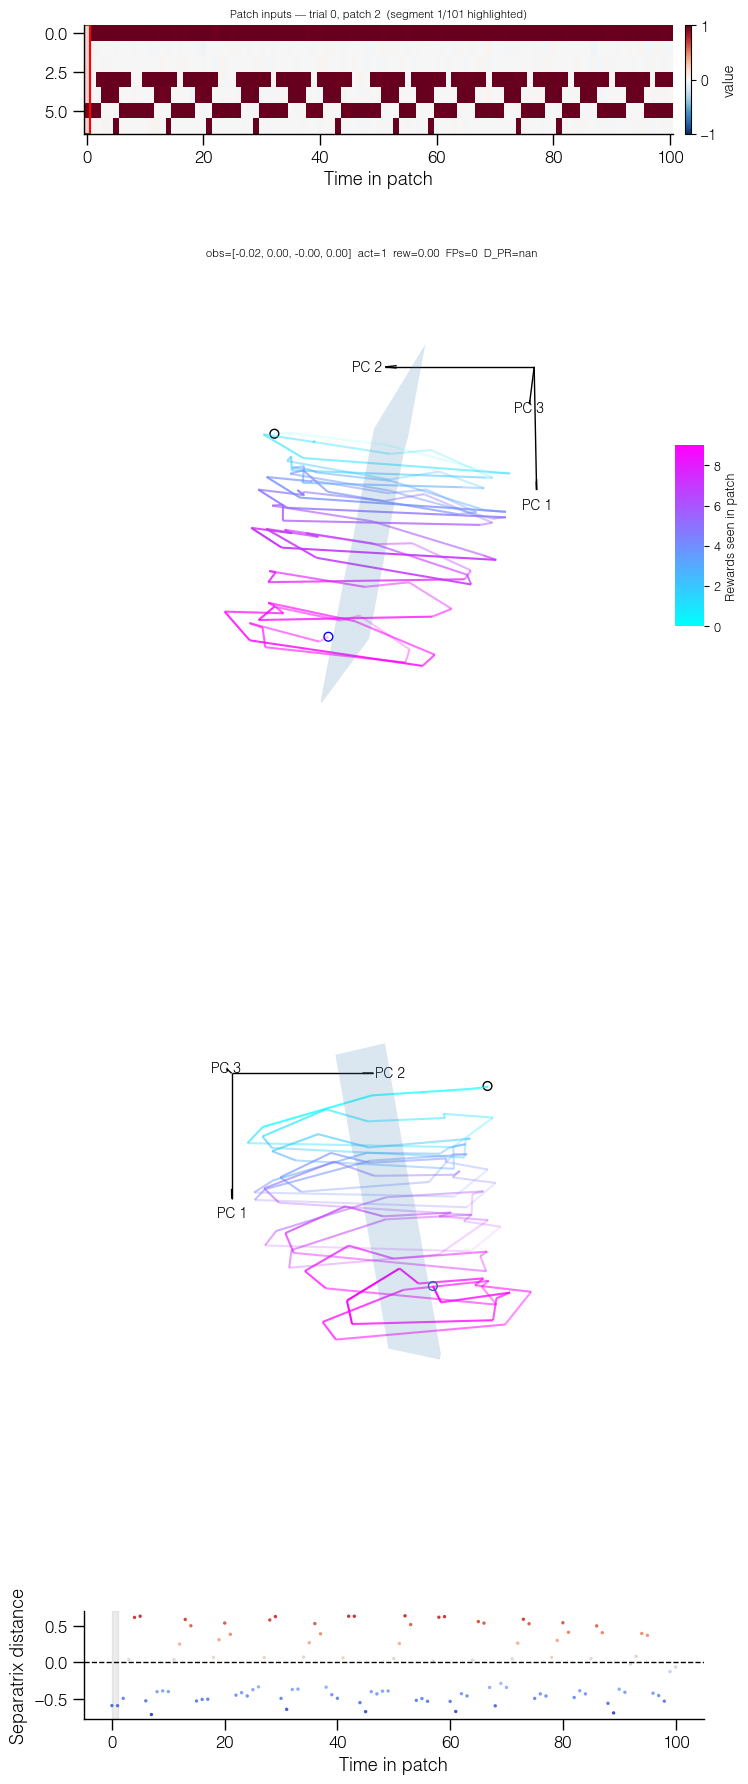

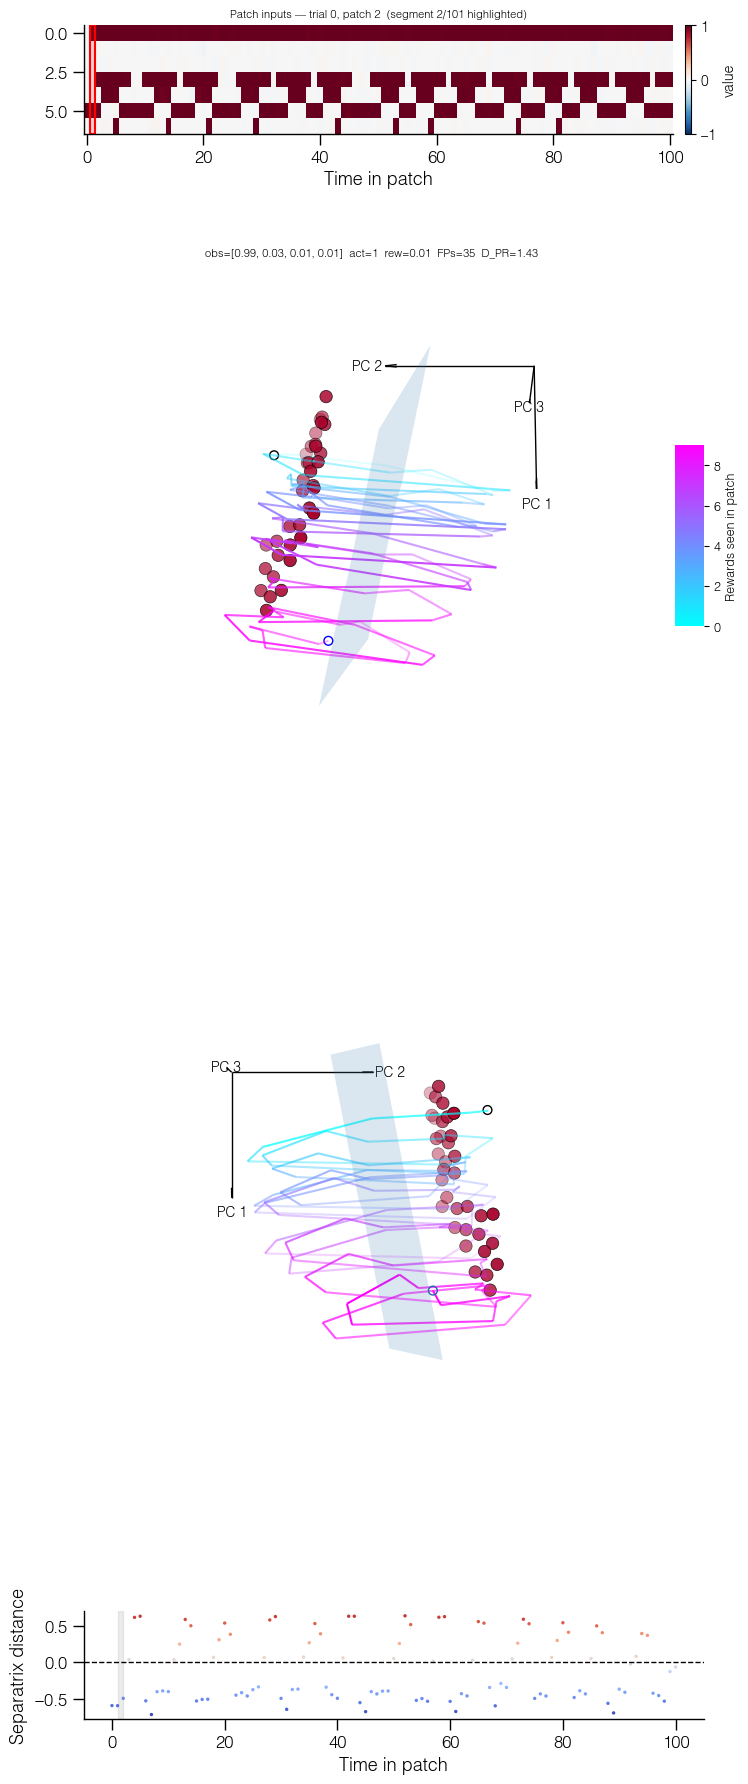

In [606]:
plot_patch_segments_with_fixed_points(
    traj_data, net_params, network, pca,
    trial_idx=0,
    patch_idx=2,
    patch_type=2,
    n_fp_attempts=300,
    unique_fp_tol=1.5e-1,
    fp_tol=2e-3,
    azim=180,
    elev=-110,
    azim2=365,
    elev2=90,
    includes_actions_and_rewards=True,
    stop_after_unique_inputs=True,
    round_inputs_for_uniqueness=True,
    traj_cmap=sns.color_palette(palette='cool', as_cmap=True),
    plot_current_segment=False,
    target_inputs=[
        None,
        [1, 0, 0, 0, 0, 1, 0],
    ],
    save_dir=str(FIGURES_DIR / 'patch_segments_v2'),
    fp_color='#a8032c',
    lw=1.5
)


/tmp/ipykernel_2871743/4204479419.py:133: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  _fig.tight_layout()


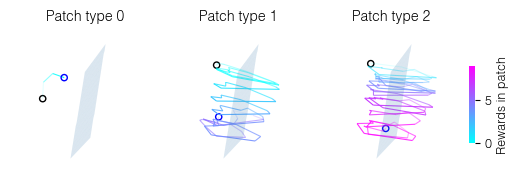

In [8]:
from nb_dynamics_plotting import _depth_alpha_lc3d
# ── 3-panel: one patch trajectory per patch type, colored by rewards ──────────
_TRIAL_IDX     = 0
_PATCH_IDX     = 2
_THRESHOLD     = 0.5
_N_STEPS       = 20000
_AZIM          = 180
_ELEV          = -110
_N_FP_ATTEMPTS = 300
_FP_TOL        = 1e-3
_FP_COLOR      = '#a8032c'
_TARGET_INPUT  = np.array([1, 0, 0, 0, 0, 1, 0], dtype=float)
_LW            = 0.8
_traj_cmap     = sns.color_palette(palette='cool', as_cmap=True)
_PATCH_TYPES   = [0, 1, 2]
_SHOW_FPS      = False

# Unpack
_n_total    = traj_data['observations'].shape[0]
_n_envs     = _n_total // _N_STEPS
_obs_all    = traj_data['observations'].reshape(_n_envs, _N_STEPS, -1)[_TRIAL_IDX]
_hidden_all = traj_data['actor_hidden'].reshape(_n_envs, _N_STEPS, -1)[_TRIAL_IDX]
_rews_all   = traj_data['rewards'].reshape(_n_envs, _N_STEPS)[_TRIAL_IDX]
_pnum_all   = traj_data['current_patch_num'].reshape(_n_envs, _N_STEPS)[_TRIAL_IDX]

_padded  = np.concatenate([[False], _obs_all[:, 0] > _THRESHOLD, [False]])
_diff    = np.diff(_padded.astype(int))
_starts  = np.where(_diff ==  1)[0]
_stops   = np.where(_diff == -1)[0]

# Extract one patch per type
_patch_records = []
for _pt in _PATCH_TYPES:
    _mask  = np.array([_pnum_all[s] == _pt for s in _starts])
    _pss   = _starts[_mask]
    _pes   = _stops[_mask]
    if _PATCH_IDX >= len(_pss):
        print(f'patch_type={_pt}: only {len(_pss)} patches — skipped')
        _patch_records.append(None)
        continue
    _p0   = _pss[_PATCH_IDX]
    _p1   = _pes[_PATCH_IDX]
    _pre  = max(0, _p0 - 1)
    _h    = _hidden_all[_pre:_p1]
    _o    = _obs_all[_pre:_p1]
    _cr   = np.cumsum(_rews_all[_pre:_p1]).astype(float)
    _pp   = pca.transform(_h)[:, :3]
    # find input_vec matching target within this patch
    _ivec = _TARGET_INPUT
    for _t in range(len(_o)):
        if np.array_equal(np.clip(np.round(_o[_t]), 0, 1).astype(int),
                          _TARGET_INPUT.astype(int)):
            _ivec = _o[_t]
            break
    _patch_records.append((_pt, _pp, _cr, _ivec))

# Shared colour scale
_all_cum = np.concatenate([r[2] for r in _patch_records if r is not None])
_gnorm   = Normalize(vmin=0, vmax=float(_all_cum.max()))

# Fixed points per patch type
_fps_by_pt = {}
if _SHOW_FPS:
    _key     = jax.random.PRNGKey(42)
    _indices = jax.random.randint(_key, (_N_FP_ATTEMPTS,), 0, traj_data['actor_hidden'].shape[0])
    _h_inits = jnp.array(traj_data['actor_hidden'][_indices])
    for _rec in _patch_records:
        if _rec is None:
            continue
        _pt_, _pp_, _cr_, _ivec_ = _rec
        _fps_, _conv_, _ = find_fixed_points_batch(
            params=net_params, network=network, input_vec=_ivec_,
            h_inits=_h_inits, max_steps=60000, learning_rate=0.001,
            tolerance=_FP_TOL, verbose=False,
        )
        _fps_by_pt[_pt_] = filter_unique_fixed_points(_fps_, _conv_)

# Figure
_fig = plt.figure(figsize=(6, 3))
_gs   = _fig.add_gridspec(1, 4, width_ratios=[1, 1, 1, 0.04], wspace=0.02)
_axes = [_fig.add_subplot(_gs[0, i], projection='3d') for i in range(3)]
_ax_cb = _fig.add_subplot(_gs[0, 3])
_active = []
for _ax, _rec in zip(_axes, _patch_records):
    if _rec is None:
        _ax.set_visible(False)
        continue
    _active.append(_ax)
    _pt_, _pp_, _cr_, _ivec_ = _rec
    _full_pts  = _pp_.reshape(-1, 1, 3)
    _full_segs = np.concatenate([_full_pts[:-1], _full_pts[1:]], axis=1)
    _colors    = _traj_cmap(_gnorm(_cr_[:-1]))
    _lc = _depth_alpha_lc3d(_full_segs, _colors, _ELEV, _AZIM, linewidth=_LW, zorder=1)
    _ax.add_collection3d(_lc)
    _ufps = _fps_by_pt.get(_pt_)
    if _ufps is not None and len(_ufps) > 0:
        _fp_proj = pca.transform(np.array(_ufps))[:, :3]
        _ax.scatter(_fp_proj[:, 0], _fp_proj[:, 1], _fp_proj[:, 2],
                    s=80, marker='o', color=_FP_COLOR,
                    edgecolors='k', linewidths=0.5, zorder=6)
    _ax.scatter(*_pp_[0], s=20, marker='o', facecolors='none',
            edgecolors='black', zorder=7)
    _ax.scatter(*_pp_[-1], s=20, marker='o', facecolors='none',
                edgecolors='blue', zorder=7)
    _ax.view_init(elev=_ELEV, azim=_AZIM)
    _ax.set_title(f'Patch type {_pt_}', fontsize=10)
    _ax.set_axis_off()

# Sync axis limits first, then draw separatrix planes at shared scale
for _get, _set in [('get_xlim3d', 'set_xlim3d'),
                   ('get_ylim3d', 'set_ylim3d'),
                   ('get_zlim3d', 'set_zlim3d')]:
    _lo = min(getattr(_ax, _get)()[0] for _ax in _active)
    _hi = max(getattr(_ax, _get)()[1] for _ax in _active)
    for _ax in _active:
        getattr(_ax, _set)(_lo, _hi)

for _ax in _active:
    add_separatrix_plane(_ax, net_params, pca)

# Shared colorbar (1/3 height, centered)
_sm = plt.cm.ScalarMappable(cmap=_traj_cmap, norm=_gnorm)
_sm.set_array([])
_pos = _ax_cb.get_position()
_nh  = _pos.height / 3
_ax_cb.set_position([_pos.x0, _pos.y0 + _pos.height / 2 - _nh / 2, _pos.width, _nh])
_cbar = _fig.colorbar(_sm, cax=_ax_cb, orientation='vertical',
                      label='Rewards in patch')
_cbar.outline.set_visible(False)
_cbar.ax.yaxis.label.set_size(9)
_ax_cb.tick_params(labelsize=9)

_fig.tight_layout()
_save_dir = str(FIGURES_DIR / 'patch_types_3panel')
os.makedirs(_save_dir, exist_ok=True)
for _ext, _dpi in (('pdf', None), ('png', 150), ('svg', None)):
    _fig.savefig(os.path.join(_save_dir, f'patch_types_3panel.{_ext}'),
                 bbox_inches='tight', **(dict(dpi=_dpi) if _dpi else {}))
plt.show()

/tmp/ipykernel_2871743/2023586691.py:39: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  _fig2.tight_layout()


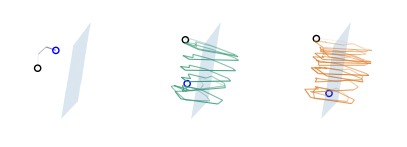

In [ ]:
import matplotlib.colors as _mcolors

# ── 3-panel: one patch trajectory per patch type, colored by patch type ───────
PTYPE_COLOR = {2: '#E1812C', 1: '#3A9E78', 0: '#7E6BAA'}   # orange / green / purple

_fig2 = plt.figure(figsize=(5, 3))
_gs2  = _fig2.add_gridspec(1, 3, wspace=0.02)
_axes2 = [_fig2.add_subplot(_gs2[0, i], projection='3d') for i in range(3)]
_active2 = []

for _ax, _rec in zip(_axes2, _patch_records):
    if _rec is None:
        _ax.set_visible(False)
        continue
    _active2.append(_ax)
    _pt_, _pp_, _cr_, _ivec_ = _rec
    _full_pts  = _pp_.reshape(-1, 1, 3)
    _full_segs = np.concatenate([_full_pts[:-1], _full_pts[1:]], axis=1)
    _color_rgba = np.array(_mcolors.to_rgba(PTYPE_COLOR[_pt_]))
    _seg_colors = np.tile(_color_rgba, (len(_full_segs), 1))
    _lc2 = _depth_alpha_lc3d(_full_segs, _seg_colors, _ELEV, _AZIM, linewidth=_LW, zorder=1)
    _ax.add_collection3d(_lc2)
    _ax.scatter(*_pp_[0], s=20, marker='o', facecolors='none', edgecolors='black', zorder=7)
    _ax.scatter(*_pp_[-1], s=20, marker='o', facecolors='none', edgecolors='blue', zorder=7)
    _ax.view_init(elev=_ELEV, azim=_AZIM)
    _ax.set_axis_off()

for _get, _set in [('get_xlim3d', 'set_xlim3d'),
                   ('get_ylim3d', 'set_ylim3d'),
                   ('get_zlim3d', 'set_zlim3d')]:
    _lo2 = min(getattr(_ax, _get)()[0] for _ax in _active2)
    _hi2 = max(getattr(_ax, _get)()[1] for _ax in _active2)
    for _ax in _active2:
        getattr(_ax, _set)(_lo2, _hi2)

for _ax in _active2:
    add_separatrix_plane(_ax, net_params, pca)

_fig2.tight_layout()
_save_dir2 = str(FIGURES_DIR / 'patch_types_3panel_ptype_color')
os.makedirs(_save_dir2, exist_ok=True)
for _ext, _dpi in (('pdf', None), ('png', 150), ('svg', None)):
    _fig2.savefig(os.path.join(_save_dir2, f'patch_types_3panel_ptype_color.{_ext}'),
                  bbox_inches='tight', **(dict(dpi=_dpi) if _dpi else {}))
plt.show()

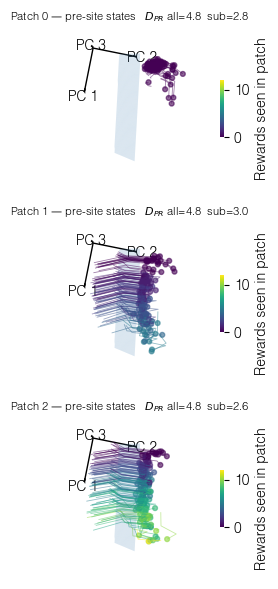

In [458]:
# ── Pre-patch states: 3D scatter by patch type (stacked vertically) ──────────
from nb_dynamics_plotting import _style_3d_ax
# Load all available envs from the trajectory file to capture all patch types
N_STEPS    = 20000
MAX_EVENTS = 150  # max events to plot per patch type

traj_data_multi = {}
for env_idx in range(len(traj_data_raw)):
    td_env = parse_behavioral_data(traj_data_raw[env_idx])
    for key in td_env:
        if key in traj_data_multi:
            traj_data_multi[key] = np.concatenate([traj_data_multi[key], td_env[key]], axis=0)
        else:
            traj_data_multi[key] = td_env[key]

pca_multi = PCA()
pca_multi.fit(traj_data_multi['actor_hidden'])

COLOR_BY   = 'rewards_seen_in_patch'
CBAR_LABEL = 'Rewards seen in patch'
AZIM, ELEV = 370, 90

events = find_pre_odor_onset_states(traj_data_multi, max_lookahead=3, include_first=True)

sub_hidden = events['hidden'][:, 0]
sub_next1  = events['hidden'][:, 1]
sub_next2  = events['hidden'][:, 2]
sub_next3  = events['hidden'][:, 3]

_n_envs_m = max(1, traj_data_multi[COLOR_BY].shape[0] // N_STEPS)
raw_c      = traj_data_multi[COLOR_BY].reshape(_n_envs_m, N_STEPS, -1)[:, :, 0].T
sub_colors = raw_c[events['pre_t_idx'], events['trial_idx']]

kernel = np.array(net_params['params']['actor']['kernel'])
w      = kernel[:, 0] - kernel[:, 1]
b_diff = float(np.array(net_params['params']['actor']['bias'])[0] -
               np.array(net_params['params']['actor']['bias'])[1])
w_norm = np.linalg.norm(w)

raw_patch   = traj_data_multi['current_patch_num'].reshape(_n_envs_m, N_STEPS, -1).transpose(1, 0, 2)[:, :, 0]
event_patch = raw_patch[events['pre_t_idx'], events['trial_idx']].astype(int)
patch_vals  = sorted(np.unique(event_patch))
n_patches   = len(patch_vals)
cmap  = plt.cm.viridis
norm  = Normalize(vmin=np.nanmin(sub_colors), vmax=np.nanmax(sub_colors))
rng   = np.random.default_rng(0)
d_pr_all = participation_ratio(traj_data_multi['actor_hidden'])

def _add_traj_lines(ax, p0, p1, p2, p3, colors):
    segs = np.stack([p0, p1, p2, p3], axis=1)
    lc = Line3DCollection(segs, colors=cmap(norm(colors)),
                          linewidths=0.6, alpha=0.5, zorder=1)
    ax.add_collection3d(lc)

scale = 0.5
fig = plt.figure(figsize=(scale * 5, scale * 4 * n_patches))
# Pre-compute global PC limits across all patch types so all subplots share the same scale
_all_pc = np.concatenate([
    pca_multi.transform(_h)[:, :3]
    for _pnum in patch_vals
    for _h in [sub_hidden[event_patch == _pnum],
               sub_next1[event_patch == _pnum],
               sub_next2[event_patch == _pnum],
               sub_next3[event_patch == _pnum]]
], axis=0)
_xlim = (float(_all_pc[:, 0].min()), float(_all_pc[:, 0].max()))
_ylim = (float(_all_pc[:, 1].min()), float(_all_pc[:, 1].max()))
_zlim = (float(_all_pc[:, 2].min()), float(_all_pc[:, 2].max()))

patch_axes = []
for row, pnum in enumerate(patch_vals):
    mask = event_patch == pnum
    h0 = sub_hidden[mask]; h1 = sub_next1[mask]; h2 = sub_next2[mask]
    h3 = sub_next3[mask];  sc = sub_colors[mask]
    keep = rng.choice(len(h0), size=min(len(h0), MAX_EVENTS), replace=False)
    h0, h1, h2, h3, sc = h0[keep], h1[keep], h2[keep], h3[keep], sc[keep]
    d_pr_sub = participation_ratio(h0) if len(h0) > 1 else float('nan')

    ax3     = fig.add_subplot(n_patches, 1, row + 1, projection='3d')
    patch_axes.append(ax3)
    ax3.set_title(
        f'Patch {pnum} — pre-site states   $D_{{PR}}$ all={d_pr_all:.1f}  sub={d_pr_sub:.1f}',
        fontsize=8,
    )

    pts_pre = pca_multi.transform(h0)[:, :3]
    pts_n1  = pca_multi.transform(h1)[:, :3]
    pts_n2  = pca_multi.transform(h2)[:, :3]
    pts_n3  = pca_multi.transform(h3)[:, :3]
    
    _add_traj_lines(ax3, pts_pre, pts_n1, pts_n2, pts_n3, sc)
    ax3.scatter(pts_pre[:, 0], pts_pre[:, 1], pts_pre[:, 2],
                c=sc, cmap=cmap, norm=norm, s=12, alpha=0.6, depthshade=True)
    ax3.set_xlim3d(*_xlim); ax3.set_ylim3d(*_ylim); ax3.set_zlim3d(*_zlim)
    _style_3d_ax(ax3, norm, cmap, CBAR_LABEL, autoscale=False)
    add_separatrix_plane(ax3, net_params, pca_multi)
    ax3.view_init(elev=ELEV, azim=AZIM)

fig.tight_layout()
fig.savefig(FIGURES_DIR / 'pre_patch_rewards.png', dpi=150, bbox_inches='tight')
fig.savefig(FIGURES_DIR / 'pre_patch_rewards.svg', bbox_inches='tight')
plt.show()


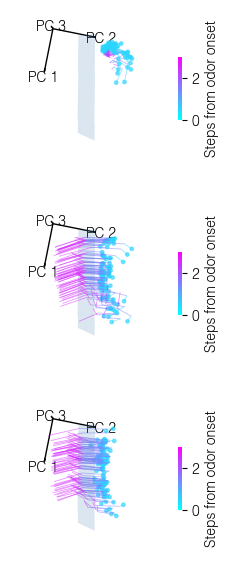

In [397]:
# ── Pre-patch states: colored by lookahead timestep ────────────────────────────
from nb_dynamics_plotting import _style_3d_ax
# Load all available envs from the trajectory file to capture all patch types
N_STEPS    = 20000
MAX_EVENTS = 100  # max events to plot per patch type

traj_data_multi = {}
for env_idx in range(len(traj_data_raw)):
    td_env = parse_behavioral_data(traj_data_raw[env_idx])
    for key in td_env:
        if key in traj_data_multi:
            traj_data_multi[key] = np.concatenate([traj_data_multi[key], td_env[key]], axis=0)
        else:
            traj_data_multi[key] = td_env[key]

pca_multi = PCA()
pca_multi.fit(traj_data_multi['actor_hidden'])

N_LOOKAHEAD = 3
AZIM, ELEV = 370, 90

events = find_pre_odor_onset_states(traj_data_multi, max_lookahead=3, include_first=True)

sub_hidden = events['hidden'][:, 0]
sub_next1  = events['hidden'][:, 1]
sub_next2  = events['hidden'][:, 2]
sub_next3  = events['hidden'][:, 3]

_n_envs_m = max(1, traj_data_multi['actor_hidden'].shape[0] // N_STEPS)

raw_patch   = traj_data_multi['current_patch_num'].reshape(_n_envs_m, N_STEPS, -1).transpose(1, 0, 2)[:, :, 0]
event_patch = raw_patch[events['pre_t_idx'], events['trial_idx']].astype(int)
patch_vals  = sorted(np.unique(event_patch))
n_patches   = len(patch_vals)
cmap_la  = plt.cm.cool
norm_la  = Normalize(vmin=0, vmax=N_LOOKAHEAD)
step_colors = [cmap_la(norm_la(i + 0.5)) for i in range(N_LOOKAHEAD)]
d_pr_all = participation_ratio(traj_data_multi['actor_hidden'])
rng = np.random.default_rng(0)

def _add_lookahead_lines(ax, pts_list, colors):
    for i, (pa, pb) in enumerate(zip(pts_list[:-1], pts_list[1:])):
        segs = np.stack([pa, pb], axis=1)
        lc = Line3DCollection(segs, color=colors[i],
                              linewidths=0.6, alpha=0.5, zorder=1)
        ax.add_collection3d(lc)

scale = 0.5
fig = plt.figure(figsize=(scale * 5, scale * 4 * n_patches))
# Pre-compute global PC limits across all patch types so all subplots share the same scale
_all_pc = np.concatenate([
    pca_multi.transform(_h)[:, :3]
    for _pnum in patch_vals
    for _h in [sub_hidden[event_patch == _pnum],
               sub_next1[event_patch == _pnum],
               sub_next2[event_patch == _pnum],
               sub_next3[event_patch == _pnum]]
], axis=0)
_xlim = (float(_all_pc[:, 0].min()), float(_all_pc[:, 0].max()))
_ylim = (float(_all_pc[:, 1].min()), float(_all_pc[:, 1].max()))
_zlim = (float(_all_pc[:, 2].min()), float(_all_pc[:, 2].max()))

patch_axes = []
for row, pnum in enumerate(patch_vals):
    mask = event_patch == pnum
    h0 = sub_hidden[mask]; h1 = sub_next1[mask]; h2 = sub_next2[mask]
    h3 = sub_next3[mask]
    keep = rng.choice(len(h0), size=min(len(h0), MAX_EVENTS), replace=False)
    h0, h1, h2, h3 = h0[keep], h1[keep], h2[keep], h3[keep]
    d_pr_sub = participation_ratio(h0) if len(h0) > 1 else float('nan')

    ax3     = fig.add_subplot(n_patches, 1, row + 1, projection='3d')
    patch_axes.append(ax3)

    pts_pre = pca_multi.transform(h0)[:, :3]
    pts_n1  = pca_multi.transform(h1)[:, :3]
    pts_n2  = pca_multi.transform(h2)[:, :3]
    pts_n3  = pca_multi.transform(h3)[:, :3]
    
    _add_lookahead_lines(ax3, [pts_pre, pts_n1, pts_n2, pts_n3], step_colors)
    ax3.scatter(pts_pre[:, 0], pts_pre[:, 1], pts_pre[:, 2],
                color=step_colors[0], s=6, alpha=0.6, depthshade=True)
    ax3.set_xlim3d(*_xlim); ax3.set_ylim3d(*_ylim); ax3.set_zlim3d(*_zlim)
    _style_3d_ax(ax3, norm_la, cmap_la, 'Steps from odor onset', autoscale=False)
    add_separatrix_plane(ax3, net_params, pca_multi)
    ax3.view_init(elev=ELEV, azim=AZIM)

fig.tight_layout()
fig.savefig(FIGURES_DIR / 'pre_patch_lookahead.png', dpi=150, bbox_inches='tight')
fig.savefig(FIGURES_DIR / 'pre_patch_lookahead.svg', bbox_inches='tight')
plt.show()


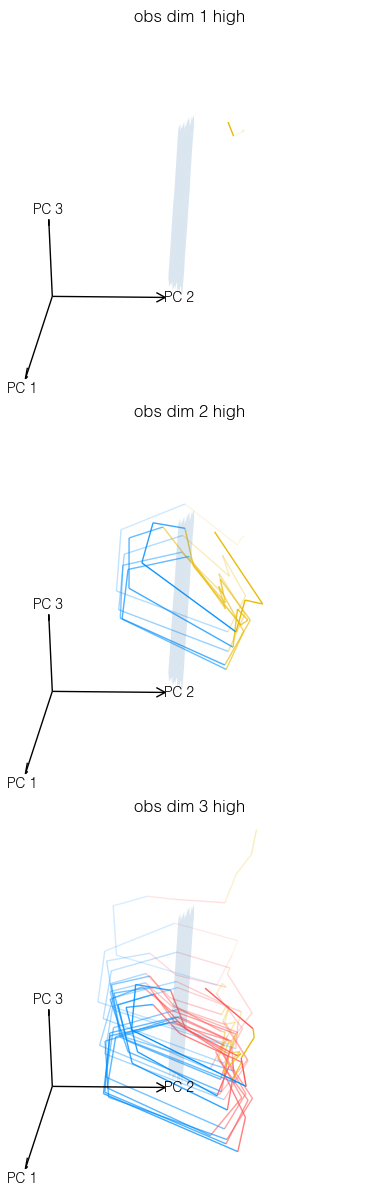

In [398]:
fig = plot_patch_trajectories_3d(
    traj_data,
    max_trajectories=1,
    seed=0,
    params=net_params,
    pca=pca,
    rz=-90, rx=0, ry=20,
    input_color_map=[
        (np.array([1, 0, 0, 1, 0, 1, 0]), '#ff5555'),
        (np.array([1, 0, 0, 1, 1, 0, 0]), '#008fff'),
        (np.array([1, 0, 0, 1, 1, 0, 1]), '#008fff'),
        (np.array([1, 0, 0, 0, 0, 1, 0]), '#e7b900'),
    ],
    zlim=(-0.4, 0.4),
)
fig.savefig(FIGURES_DIR / 'patch_trajectories.png', dpi=150, bbox_inches='tight')
fig.savefig(FIGURES_DIR / 'patch_trajectories.svg', bbox_inches='tight')


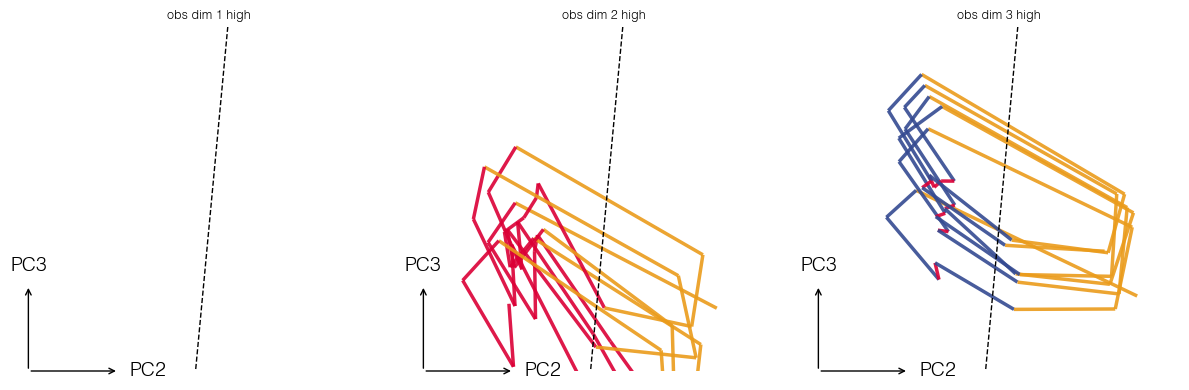

In [631]:
fig2d = plot_patch_trajectories_2d(
    traj_data,
    max_trajectories=1,
    seed=1,
    params=net_params,
    pca=pca,
    pc_x=1,
    pc_y=2,
    input_color_map=[
        (np.array([1, 0, 0, 1, 0, 1, 0]), '#344a91'),
        (np.array([1, 0, 0, 1, 1, 0, 0]), '#ea9b1b'),
        (np.array([1, 0, 0, 1, 1, 0, 1]), '#ea9b1b'),
        (np.array([1, 0, 0, 0, 0, 1, 0]), '#db0036'),
    ],
    xlim=(0.8, -1.2),
    ylim=(0.2, -0.6),
    min_timesteps=5,
    max_timesteps=50,
    lw=2.5,
)
fig2d.savefig(FIGURES_DIR / 'patch_trajectories_2d.png', dpi=150, bbox_inches='tight')
fig2d.savefig(FIGURES_DIR / 'patch_trajectories_2d.svg', bbox_inches='tight')


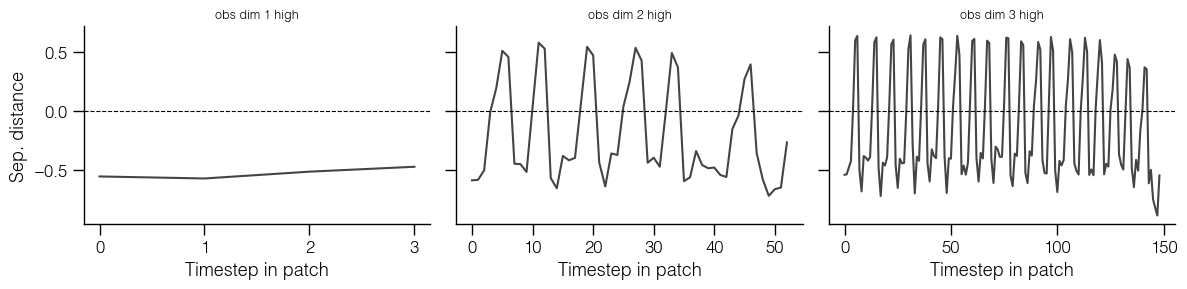

In [400]:
# ── Sep distance over time for the trajectories selected in the 2D plot above ─
# Uses the same seed / max_trajectories so the trajectories match exactly.

_SEED          = 3
_MAX_TRAJ      = 1
_THRESHOLD     = 0.5
_STEPS_PER_ENV = 20000
_OBS_DIMS      = [(1, 'obs dim 1 high'), (2, 'obs dim 2 high'), (3, 'obs dim 3 high')]

_kernel = np.array(net_params['params']['actor']['kernel'])
_w      = _kernel[:, 0] - _kernel[:, 1]
_b_diff = float(np.array(net_params['params']['actor']['bias'])[0] -
                np.array(net_params['params']['actor']['bias'])[1])
_w_norm = np.linalg.norm(_w)
_sep    = lambda h: (h @ _w + _b_diff) / _w_norm

_n_envs  = max(1, traj_data['actor_hidden'].shape[0] // _STEPS_PER_ENV)
_obs     = traj_data['observations'].reshape(_n_envs, _STEPS_PER_ENV, -1).transpose(1, 0, 2)
_hidden  = traj_data['actor_hidden'].reshape(_n_envs, _STEPS_PER_ENV, -1).transpose(1, 0, 2)
_in_pat  = traj_data['agent_in_patch'].reshape(_n_envs, _STEPS_PER_ENV).T
_periods = extract_patch_starts_and_stops(_in_pat)

fig_sd, axes_sd = plt.subplots(1, len(_OBS_DIMS),
                                figsize=(4 * len(_OBS_DIMS), 3),
                                sharey=True)

for ax, (dim, title) in zip(axes_sd, _OBS_DIMS):
    patch_trajs = []
    for trial, trial_periods in enumerate(_periods):
        for start, end in trial_periods:
            if np.any(_obs[start:end, trial, dim] > _THRESHOLD):
                patch_trajs.append(_hidden[start:end, trial, :])

    if not patch_trajs:
        ax.set_visible(False)
        continue

    rng_sel  = np.random.default_rng(_SEED)
    idx      = rng_sel.choice(len(patch_trajs),
                              size=min(_MAX_TRAJ, len(patch_trajs)), replace=False)
    for i in idx:
        sd = _sep(patch_trajs[i])
        ax.plot(np.arange(len(sd)), sd, lw=1.5, color='#444')

    ax.axhline(0, color='k', lw=0.8, ls='--')
    ax.set_title(title, fontsize=9)
    ax.set_xlabel('Timestep in patch', fontsize=8)
    if ax is axes_sd[0]:
        ax.set_ylabel('Sep. distance', fontsize=8)
    format_plot(ax)

fig_sd.tight_layout()
fig_sd.savefig(FIGURES_DIR / 'patch_traj_sep_dist.png', dpi=150, bbox_inches='tight')
fig_sd.savefig(FIGURES_DIR / 'patch_traj_sep_dist.svg', bbox_inches='tight')
plt.show()


Fixed points for [1. 0. 0. 0. 0. 1. 0.]: 44 found


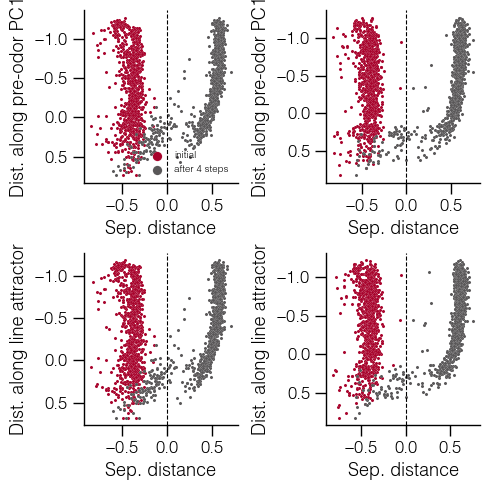

In [634]:
# ── Sep distance vs PC projection, by patch type ────────────────────────────
# For patch types 1 & 2, two x-axis variants:
#   (A) projection onto pre-odor PC1  (PCA fit to all initial pre-odor states)
#   (B) projection onto first PC of FPs for input [1, 0, 0, 0, 0, 1, 0]
# Orange = initial state, blue = state after N_LOOKAHEAD steps

N_STEPS       = 20000
N_LOOKAHEAD   = 4
PATCH_TYPES   = [1, 2]
FP_INPUT      = np.array([1, 0, 0, 0, 0, 1, 0], dtype=float)
N_FP_ATTEMPTS = 300
FP_TOL        = 1e-3
COLOR_INIT    = '#e06c4e'
COLOR_LATE    = '#5b7fa6'
MAX_EVENTS    = 1000

# --- collect all envs ---
traj_data_m = {}
for env_idx in range(len(traj_data_raw)):
    td_env = parse_behavioral_data(traj_data_raw[env_idx])
    for key in td_env:
        if key in traj_data_m:
            traj_data_m[key] = np.concatenate([traj_data_m[key], td_env[key]], axis=0)
        else:
            traj_data_m[key] = td_env[key]

events = find_pre_odor_onset_states(traj_data_m, max_lookahead=N_LOOKAHEAD, include_first=True)
sub_hidden = events['hidden'][:, 0]
sub_late   = events['hidden'][:, N_LOOKAHEAD]

_n_envs_m   = max(1, traj_data_m['actor_hidden'].shape[0] // N_STEPS)
raw_patch   = traj_data_m['current_patch_num'].reshape(_n_envs_m, N_STEPS, -1).transpose(1, 0, 2)[:, :, 0]
event_patch = raw_patch[events['pre_t_idx'], events['trial_idx']].astype(int)

# sep distance
kernel = np.array(net_params['params']['actor']['kernel'])
w      = kernel[:, 0] - kernel[:, 1]
b_diff = float(np.array(net_params['params']['actor']['bias'])[0] -
               np.array(net_params['params']['actor']['bias'])[1])
w_norm = np.linalg.norm(w)
sep    = lambda h: (h @ w + b_diff) / w_norm

d0    = sep(sub_hidden)
dlate = sep(sub_late)

# --- pre-odor PC1 ---
pca_preo     = PCA(n_components=1).fit(sub_hidden)
preo_pc1_all = sub_hidden @ pca_preo.components_[0]

# --- FP PC1 ---
_rng_fp  = jax.random.key(42)
_indices = np.array(jax.random.randint(_rng_fp, (N_FP_ATTEMPTS,), 0, traj_data_m['actor_hidden'].shape[0]))
_h_inits = jnp.array(traj_data_m['actor_hidden'][_indices])
_fps, _conv, _ = find_fixed_points_batch(
    params=net_params, network=network, input_vec=jnp.array(FP_INPUT),
    h_inits=_h_inits, max_steps=60000, learning_rate=0.001,
    tolerance=FP_TOL, verbose=False,
)
unique_fps = np.array(filter_unique_fixed_points(_fps, _conv))
print(f'Fixed points for {FP_INPUT}: {len(unique_fps)} found')

if len(unique_fps) >= 2:
    fp_pc1_dir = PCA(n_components=1).fit(unique_fps).components_[0]
elif len(unique_fps) == 1:
    fp_pc1_dir = unique_fps[0] - sub_hidden.mean(axis=0)
    fp_pc1_dir /= np.linalg.norm(fp_pc1_dir)
else:
    fp_pc1_dir = None
    print('No FPs found — FP-PC1 version will be skipped')

fp_pc1_all = sub_hidden @ fp_pc1_dir if fp_pc1_dir is not None else None

# --- plot ---
rng_ds = np.random.default_rng(1)

x_axes = [('preo_pc1', preo_pc1_all, 'Dist. along pre-odor PC1')]
if fp_pc1_all is not None:
    x_axes.append(('fp_pc1', fp_pc1_all, 'Dist. along line attractor'))

n_rows = len(x_axes)
fig, axes = plt.subplots(n_rows, len(PATCH_TYPES),
                         figsize=(2.5 * len(PATCH_TYPES), 2.5 * n_rows),
                         squeeze=False)

for row, (x_key, x_all, x_label) in enumerate(x_axes):
    for col, ptype in enumerate(PATCH_TYPES):
        ax   = axes[row, col]
        mask = event_patch == ptype
        x_s  = x_all[mask]; d0_s = d0[mask]; dl_s = dlate[mask]
        keep = rng_ds.choice(len(x_s), size=min(len(x_s), MAX_EVENTS), replace=False)
        x_s, d0_s, dl_s = x_s[keep], d0_s[keep], dl_s[keep]

        ax.scatter(d0_s, x_s, c='#a8032c', s=5, alpha=1, linewidths=0.06,
                   label='initial', rasterized=False, edgecolor='white')
        ax.scatter(dl_s, x_s, c='#595758', s=5, alpha=1, linewidths=0.06,
                   label=f'after {N_LOOKAHEAD} steps', rasterized=False, edgecolor='white')
        ax.axvline(0, color='k', lw=0.8, ls='--')
        ax.set_xlabel('Sep. distance', fontsize=8)
        ax.set_ylabel(x_label, fontsize=8)
        if col == 0 and row == 0:
            ax.legend(fontsize=7, markerscale=3, frameon=False)
        format_plot(ax)
        ax.invert_yaxis()

fig.tight_layout()
fig.savefig(FIGURES_DIR / 'sep_dist_vs_pc_proj.png', dpi=150, bbox_inches='tight')
fig.savefig(FIGURES_DIR / 'sep_dist_vs_pc_proj.svg', bbox_inches='tight')
plt.show()


/tmp/ipykernel_1318480/3159903254.py:48: UserWarning: Glyph 8594 (\N{RIGHTWARDS ARROW}) missing from font(s) Helvetica Light.
  _fig_arr.tight_layout()
/tmp/ipykernel_1318480/3159903254.py:49: UserWarning: Glyph 8594 (\N{RIGHTWARDS ARROW}) missing from font(s) Helvetica Light.
  _fig_arr.savefig(FIGURES_DIR / 'sep_dist_vs_pc_proj_arrows.png', dpi=150, bbox_inches='tight')
/tmp/ipykernel_1318480/3159903254.py:50: UserWarning: Glyph 8594 (\N{RIGHTWARDS ARROW}) missing from font(s) Helvetica Light.
  _fig_arr.savefig(FIGURES_DIR / 'sep_dist_vs_pc_proj_arrows.svg', bbox_inches='tight')


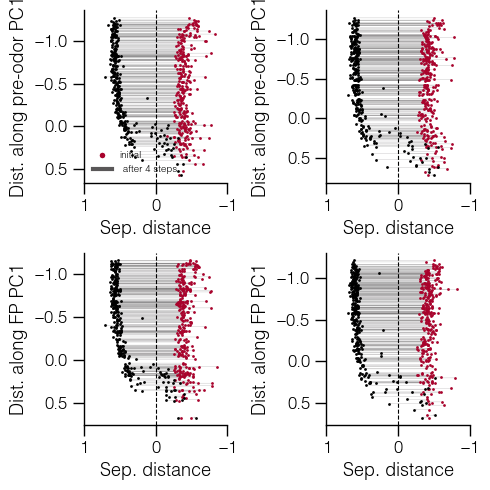

In [551]:
# ── Arrow version: Sep distance vs PC projection ─────────────────────────────
# For each event, draws an arrow from the initial state to the state after N_LOOKAHEAD steps.
# All arrows are horizontal (y = pre-odor/FP PC1 projection of the initial state).
MAX_EVENTS = 300

_rng_arr = np.random.default_rng(1)   # same seed as the scatter version

_fig_arr, _axes_arr = plt.subplots(n_rows, len(PATCH_TYPES),
                                    figsize=(2.5 * len(PATCH_TYPES), 2.5 * n_rows),
                                    squeeze=False)

for row, (x_key, x_all, x_label) in enumerate(x_axes):
    for col, ptype in enumerate(PATCH_TYPES):
        ax   = _axes_arr[row, col]
        mask = event_patch == ptype
        x_s  = x_all[mask]; d0_s = d0[mask]; dl_s = dlate[mask]
        keep = _rng_arr.choice(len(x_s), size=min(len(x_s), MAX_EVENTS), replace=False)
        x_s, d0_s, dl_s = x_s[keep], d0_s[keep], dl_s[keep]

        # Arrows from (d0, x) → (dlate, x); only sep. distance changes
        ax.quiver(d0_s, x_s, dl_s - d0_s, np.zeros_like(d0_s),
                  color='#595758', alpha=0.35,
                  angles='xy', scale_units='xy', scale=1,
                  width=0.003, headwidth=4, headlength=4,
                  rasterized=True)
        # Red dot at the initial position, black dot at the end
        ax.scatter(d0_s, x_s, c='#a8032c', s=4, linewidths=0, zorder=3, rasterized=True)
        ax.scatter(dl_s, x_s, c='k',      s=4, linewidths=0, zorder=3, rasterized=True)

        ax.axvline(0, color='k', lw=0.8, ls='--')
        ax.set_xlabel('Sep. distance', fontsize=8)
        ax.set_ylabel(x_label, fontsize=8)
        if col == 0 and row == 0:
            from matplotlib.lines import Line2D
            from matplotlib.patches import FancyArrow
            _leg = [
                Line2D([0], [0], marker='o', color='w', markerfacecolor='#a8032c',
                       ms=5, label='initial'),
                Line2D([0], [0], color='#595758', lw=3,
                       label=f'→ after {N_LOOKAHEAD} steps'),
            ]
            ax.legend(handles=_leg, fontsize=7, frameon=False)
        ax.set_xlim(-1, 1)
        format_plot(ax)
        ax.invert_xaxis()
        ax.invert_yaxis()

_fig_arr.tight_layout()
_fig_arr.savefig(FIGURES_DIR / 'sep_dist_vs_pc_proj_arrows.png', dpi=150, bbox_inches='tight')
_fig_arr.savefig(FIGURES_DIR / 'sep_dist_vs_pc_proj_arrows.svg', bbox_inches='tight')
plt.show()

(2226, 4, 64)


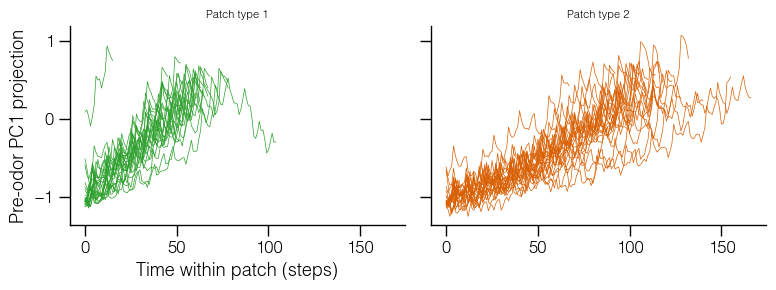

In [16]:
# ── Patch progress trajectories ───────────────────────────────────────────────
traj_data_pp = {}
for env_idx in range(len(traj_data_raw)):
    td_env = parse_behavioral_data(traj_data_raw[env_idx])
    for key in td_env:
        if key in traj_data_pp:
            traj_data_pp[key] = np.concatenate([traj_data_pp[key], td_env[key]], axis=0)
        else:
            traj_data_pp[key] = td_env[key]

# fig_pp = plot_patch_progress_trajectories(traj_data_pp, patch_types=(1, 2), n_traj=25)
# if fig_pp is not None:
#     fig_pp.savefig(FIGURES_DIR / 'patch_progress_trajectories.png', dpi=300, bbox_inches='tight')
#     fig_pp.savefig(FIGURES_DIR / 'patch_progress_trajectories.svg', bbox_inches='tight')
#     plt.show(fig_pp)
#     plt.close(fig_pp)

fig_pp_pc1 = plot_patch_progress_trajectories_pc1(traj_data_pp, patch_types=(1, 2), n_traj=25)
if fig_pp_pc1 is not None:
    fig_pp_pc1.savefig(FIGURES_DIR / 'patch_progress_trajectories_pc1.png', dpi=300, bbox_inches='tight')
    fig_pp_pc1.savefig(FIGURES_DIR / 'patch_progress_trajectories_pc1.svg', bbox_inches='tight')
    plt.show(fig_pp_pc1)
    plt.close(fig_pp_pc1)


(2264, 4, 64)


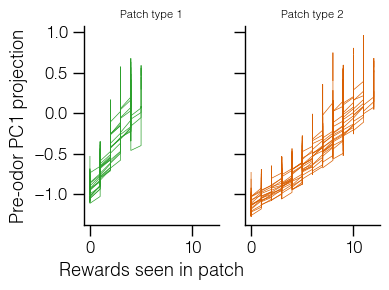

In [403]:
# \u2500\u2500 Patch progress trajectories vs rewards seen in patch \u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500
# Same plot as above, but the x-axis is rewards_seen_in_patch at each state (instead of time in patch).
fig_pp_rew = plot_patch_progress_trajectories_pc1(
    traj_data_pp, patch_types=(1, 2), n_traj=15, x_var='rewards_seen',
    figsize=(2, 3), seed=2,
)
if fig_pp_rew is not None:
    fig_pp_rew.savefig(FIGURES_DIR / 'patch_progress_trajectories_pc1_rewards_seen.png', dpi=300, bbox_inches='tight')
    fig_pp_rew.savefig(FIGURES_DIR / 'patch_progress_trajectories_pc1_rewards_seen.svg', bbox_inches='tight')
    plt.show(fig_pp_rew)
    plt.close(fig_pp_rew)


Fixed points for [1. 0. 0. 0. 0. 1. 0.]: 54 found
(2226, 4, 64)


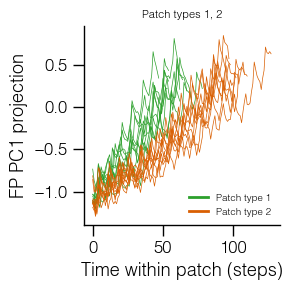

(2226, 4, 64)
(2226, 4, 64)


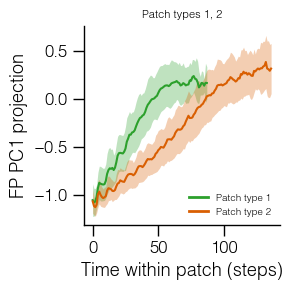

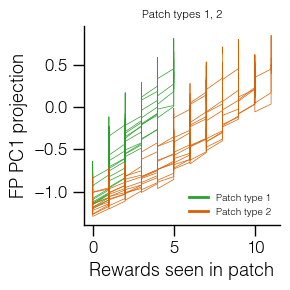

(2226, 4, 64)


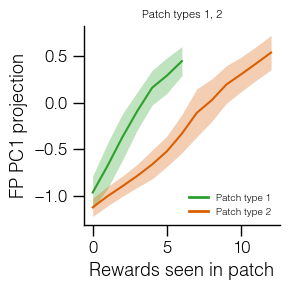

In [18]:
# \u2500\u2500 Patch progress trajectories, projected onto FP PC1 \u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500
# Same plots as above but the y-axis is the projection onto the first PC of the fixed points for
# input [1, 0, 0, 0, 0, 1, 0] (instead of pre-odor PC1).
_FP_INPUT_PP = np.array([1, 0, 0, 0, 0, 1, 0], dtype=float)
_idx_pp = np.array(jax.random.randint(jax.random.key(100), (300,), 0,
                                      traj_data_pp['actor_hidden'].shape[0]))
_h_inits_pp = jnp.array(traj_data_pp['actor_hidden'][_idx_pp])
_fps_pp, _conv_pp, _ = find_fixed_points_batch(
    params=net_params, network=network, input_vec=jnp.array(_FP_INPUT_PP),
    h_inits=_h_inits_pp, max_steps=60000, learning_rate=0.001, tolerance=1e-3, verbose=False,
)
_unique_fps_pp = np.array(filter_unique_fixed_points(_fps_pp, _conv_pp))
print(f'Fixed points for {_FP_INPUT_PP}: {len(_unique_fps_pp)} found')

if len(_unique_fps_pp) >= 2:
    _fp_pc1_dir_pp = PCA(n_components=1).fit(_unique_fps_pp).components_[0]
elif len(_unique_fps_pp) == 1:
    _fp_pc1_dir_pp = _unique_fps_pp[0] - traj_data_pp['actor_hidden'].mean(axis=0)
    _fp_pc1_dir_pp /= np.linalg.norm(_fp_pc1_dir_pp)
else:
    _fp_pc1_dir_pp = None
    print('No FPs found \u2014 FP-PC1 patch-progress plot skipped')

if _fp_pc1_dir_pp is not None:
    fig_pp_fp_pc1 = plot_patch_progress_trajectories_pc1(
        traj_data_pp, patch_types=(1, 2), n_traj=10,
        proj_dir=_fp_pc1_dir_pp, y_label='FP PC1 projection',
        figsize=(3, 3), seed=2, combined=True,
    )
    if fig_pp_fp_pc1 is not None:
        fig_pp_fp_pc1.savefig(FIGURES_DIR / 'patch_progress_trajectories_fp_pc1.png', dpi=300, bbox_inches='tight')
        fig_pp_fp_pc1.savefig(FIGURES_DIR / 'patch_progress_trajectories_fp_pc1.svg', bbox_inches='tight')
        plt.show(fig_pp_fp_pc1)
        plt.close(fig_pp_fp_pc1)

    fig_pp_fp_pc1 = plot_patch_progress_trajectories_pc1(
        traj_data_pp, patch_types=(1, 2), n_traj=10,
        proj_dir=_fp_pc1_dir_pp, y_label='FP PC1 projection',
        figsize=(3, 3), seed=2, combined=True, mean_sem=True,
    )

    fig_pp_fp_pc1 = plot_patch_progress_trajectories_pc1(
        traj_data_pp, patch_types=(1, 2), n_traj=10,
        proj_dir=_fp_pc1_dir_pp, y_label='FP PC1 projection',
        figsize=(3, 3), seed=2, x_var='rewards_seen', combined=True
    )
    if fig_pp_fp_pc1 is not None:
        fig_pp_fp_pc1.savefig(FIGURES_DIR / 'patch_progress_trajectories_fp_pc1.png', dpi=300, bbox_inches='tight')
        fig_pp_fp_pc1.savefig(FIGURES_DIR / 'patch_progress_trajectories_fp_pc1.svg', bbox_inches='tight')
        plt.show(fig_pp_fp_pc1)
        plt.close(fig_pp_fp_pc1)

    fig_pp_fp_pc1 = plot_patch_progress_trajectories_pc1(
        traj_data_pp, patch_types=(1, 2), n_traj=10,
        proj_dir=_fp_pc1_dir_pp, y_label='FP PC1 projection',
        figsize=(3, 3), seed=2, x_var='rewards_seen', combined=True, mean_sem=True,
    )

    if fig_pp_fp_pc1 is not None:
        fig_pp_fp_pc1.savefig(FIGURES_DIR / 'patch_progress_trajectories_fp_pc1_meansem.png', dpi=300, bbox_inches='tight')
        fig_pp_fp_pc1.savefig(FIGURES_DIR / 'patch_progress_trajectories_fp_pc1_meansem.svg', bbox_inches='tight')
        plt.show(fig_pp_fp_pc1)
        plt.close(fig_pp_fp_pc1)



(2204, 4, 64)


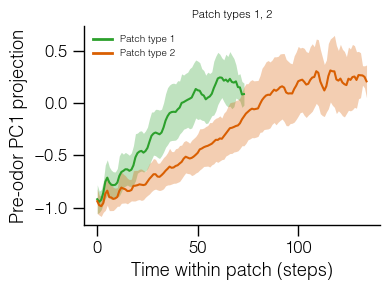

In [347]:
# \u2500\u2500 Mean +/- STD versions (both patch types overlaid) of the patch-progress plots \u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500
# (A) pre-odor PC1 vs time
fig_m = plot_patch_progress_trajectories_pc1(traj_data_pp, patch_types=(1, 2), mean_sem=True, combined=True)
if fig_m is not None:
    fig_m.savefig(FIGURES_DIR / 'patch_progress_trajectories_pc1_meansem.png', dpi=300, bbox_inches='tight')
    fig_m.savefig(FIGURES_DIR / 'patch_progress_trajectories_pc1_meansem.svg', bbox_inches='tight')
    plt.show(fig_m); plt.close(fig_m)


(2204, 4, 64)


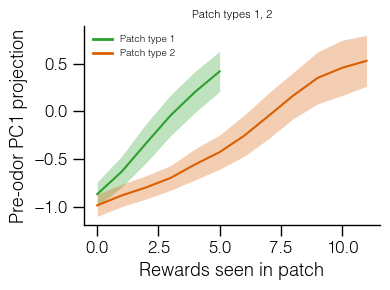

In [348]:
# (B) pre-odor PC1 vs rewards seen in patch
fig_m = plot_patch_progress_trajectories_pc1(
    traj_data_pp, patch_types=(1, 2), x_var='rewards_seen', mean_sem=True, combined=True)
if fig_m is not None:
    fig_m.savefig(FIGURES_DIR / 'patch_progress_trajectories_pc1_rewards_seen_meansem.png', dpi=300, bbox_inches='tight')
    fig_m.savefig(FIGURES_DIR / 'patch_progress_trajectories_pc1_rewards_seen_meansem.svg', bbox_inches='tight')
    plt.show(fig_m); plt.close(fig_m)


(2204, 4, 64)


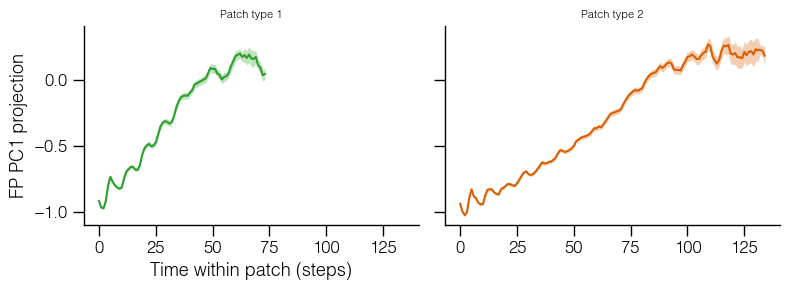

In [341]:
# (C) FP PC1 vs time
if _fp_pc1_dir_pp is not None:
    fig_m = plot_patch_progress_trajectories_pc1(
        traj_data_pp, patch_types=(1, 2),
        proj_dir=_fp_pc1_dir_pp, y_label='FP PC1 projection', mean_sem=True, combined=True)
    if fig_m is not None:
        fig_m.savefig(FIGURES_DIR / 'patch_progress_trajectories_fp_pc1_meansem.png', dpi=300, bbox_inches='tight')
        fig_m.savefig(FIGURES_DIR / 'patch_progress_trajectories_fp_pc1_meansem.svg', bbox_inches='tight')
        plt.show(fig_m); plt.close(fig_m)
